In [2]:
import pandas  as pd 

data = pd.read_csv("hf://datasets/criteo/criteo-attribution-dataset/criteo_attribution_dataset.tsv.gz", sep="\t")


d:\ds project\marketing model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
data.shape

(16468027, 22)

In [4]:
data.head()


,timestamp,uid,campaign,conversion,conversion_timestamp,conversion_id,attribution,click,click_pos,click_nb,...,time_since_last_click,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9
0,0,20073966,22589171,0,-1,-1,0,0,-1,-1,...,-1,5824233,9312274,3490278,29196072,11409686,1973606,25162884,29196072,29196072
1,2,24607497,884761,0,-1,-1,0,0,-1,-1,...,423858,30763035,9312274,14584482,29196072,11409686,1973606,22644417,9312274,21091111
2,2,28474333,18975823,0,-1,-1,0,0,-1,-1,...,8879,138937,9312274,10769841,29196072,5824237,138937,1795451,29196072,15351056
3,3,7306395,29427842,1,1449193,3063962,0,1,0,7,...,-1,28928366,26597095,12435261,23549932,5824237,1973606,9180723,29841067,29196072
4,3,25357769,13365547,0,-1,-1,0,0,-1,-1,...,-1,138937,26597094,31616034,29196072,11409684,26597096,4480345,29196072,29196072


In [5]:
conversion_corr_table = (
    data.select_dtypes(include="number")
    .corr(numeric_only=True)["conversion"]
    .drop("conversion")
    .sort_values(ascending=False)
    .rename("correlation_with_conversion")
    .to_frame()
)

display(conversion_corr_table)

# Copy as tab-separated text, suitable for pasting into a spreadsheet
print(conversion_corr_table.to_csv(sep="\t"))

,correlation_with_conversion
conversion_timestamp,0.873676
conversion_id,0.860839
attribution,0.732341
click_nb,0.551548
click_pos,0.485381
click,0.301750
cost,0.183310
cat1,0.075522
cat7,0.040488
cat6,0.019646


	correlation_with_conversion
conversion_timestamp	0.8736761813450933
conversion_id	0.8608385858655372
attribution	0.7323405742092225
click_nb	0.5515476867087974
click_pos	0.48538075007269244
click	0.30174978866992785
cost	0.1833097129397776
cat1	0.07552218702248698
cat7	0.04048770414578922
cat6	0.0196462212629848
cat2	0.017791246859386725
cat8	0.010562098773781885
timestamp	0.0021159103791034578
campaign	0.0013623125983288431
uid	-0.0007513368565416122
time_since_last_click	-0.0057494456145969425
cat3	-0.020328405429791314
cat5	-0.027388403561784406
cat9	-0.05792277422684119
cpo	-0.1647424752041409
cat4	-0.1993824371163639



In [3]:
features = [
    "timestamp",
    "campaign",
    'attribution',
    "cost",
    "cat1",
    "cat2",
    "cat3",
    "cat4",
    "cat5",
    "cat6",
    "cat7",
    "cat8",
    "cat9"
]

target = "conversion"

selected_data = data[features + [target]].copy()

X = selected_data[features]
y = selected_data[target]

print("Selected features:", features)
print("X shape:", X.shape)
print("y shape:", y.shape)  
output_path = "../data/marketing_selected_features.csv"

selected_data.to_csv(output_path, index=False)

print(f"Selected dataset saved to: {output_path}")
print(f"Dataset shape: {selected_data.shape}")


Selected features: ['timestamp', 'campaign', 'attribution', 'cost', 'cat1', 'cat2', 'cat3', 'cat4', 'cat5', 'cat6', 'cat7', 'cat8', 'cat9']
X shape: (16468027, 13)
y shape: (16468027,)
Selected dataset saved to: ../data/marketing_selected_features.csv
Dataset shape: (16468027, 14)


In [6]:
clomuns_to_drop = ['cat1','cat2','cat3', 'cat4', 'cat5', 'cat6', 'cat7', 'cat8','cat9'] 

data = data.drop(columns=clomuns_to_drop )

In [6]:
data.isna().sum()

timestamp                0
uid                      0
campaign                 0
conversion               0
conversion_timestamp     0
conversion_id            0
attribution              0
click                    0
click_pos                0
click_nb                 0
cost                     0
cpo                      0
time_since_last_click    0
dtype: int64

In [7]:
data.describe()

,timestamp,uid,campaign,conversion,conversion_timestamp,conversion_id,attribution,click,click_pos,click_nb,cost,cpo,time_since_last_click
count,1.646803e+07,1.646803e+07,1.646803e+07,1.646803e+07,1.646803e+07,1.646803e+07,1.646803e+07,1.646803e+07,1.646803e+07,1.646803e+07,1.646803e+07,1.646803e+07,1.646803e+07
mean,1.315440e+06,1.623759e+07,1.698396e+07,4.895523e-02,9.494022e+04,7.938852e+05,2.686563e-02,3.611582e-01,-8.312659e-01,-6.626017e-01,2.932556e-04,1.964287e-01,2.713594e+05
std,7.697701e+05,9.373752e+06,9.700053e+06,2.157745e-01,4.789667e+05,4.064784e+06,1.616907e-01,4.803363e-01,1.532221e+00,2.696254e+00,8.689671e-04,1.186382e-01,5.273109e+05
min,0.000000e+00,1.300000e+01,7.332200e+04,0.000000e+00,-1.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00,1.000000e-05,4.000000e-03,-1.000000e+00
25%,6.428550e+05,8.118035e+06,8.892341e+06,0.000000e+00,-1.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00,2.242494e-05,1.065391e-01,-1.000000e+00
50%,1.283518e+06,1.623691e+07,1.556893e+07,0.000000e+00,-1.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00,7.610148e-05,1.919038e-01,-1.000000e+00
75%,1.965979e+06,2.435890e+07,2.685234e+07,0.000000e+00,-1.000000e+00,-1.000000e+00,0.000000e+00,1.000000e+00,-1.000000e+00,-1.000000e+00,2.352941e-04,2.732512e-01,2.736810e+05
max,2.671199e+06,3.245875e+07,3.245211e+07,1.000000e+00,5.262888e+06,3.245852e+07,1.000000e+00,1.000000e+00,1.730000e+02,1.740000e+02,5.834483e-02,1.016311e+00,2.592000e+06


In [8]:
data["days"]  = data['timestamp'] / 86400 

print(data['days'])

0            0.000000
1            0.000023
2            0.000023
3            0.000035
4            0.000035
              ...    
16468022    30.916655
16468023    30.916655
16468024    30.916655
16468025    30.916655
16468026    30.916655
Name: days, Length: 16468027, dtype: float64


In [9]:
data[data['days'] >= 1 ]

,timestamp,uid,campaign,conversion,conversion_timestamp,conversion_id,attribution,click,click_pos,click_nb,cost,cpo,time_since_last_click,days
572035,86400,4941505,27321366,0,-1,-1,0,1,-1,-1,0.000074,0.174845,-1,1.000000
572036,86400,20954041,10341182,0,-1,-1,0,0,-1,-1,0.000293,0.043962,343408,1.000000
572037,86401,23826250,7351509,0,-1,-1,0,0,-1,-1,0.000014,0.270164,-1,1.000012
572038,86401,25969498,26852339,0,-1,-1,0,0,-1,-1,0.000012,0.264494,-1,1.000012
572039,86401,15340822,11803618,0,-1,-1,0,0,-1,-1,0.000049,0.172871,-1,1.000012
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16468022,2671199,5767906,4869923,0,-1,-1,0,1,-1,-1,0.000024,0.105551,482560,30.916655
16468023,2671199,6852682,10002432,0,-1,-1,0,0,-1,-1,0.000031,0.152418,971748,30.916655
16468024,2671199,16638720,7061828,0,-1,-1,0,0,-1,-1,0.000067,0.189066,268431,30.916655
16468025,2671199,3032300,5061834,0,-1,-1,0,1,-1,-1,0.000050,0.301084,-1,30.916655


In [10]:
data[data['days'] < 1 ]

,timestamp,uid,campaign,conversion,conversion_timestamp,conversion_id,attribution,click,click_pos,click_nb,cost,cpo,time_since_last_click,days
0,0,20073966,22589171,0,-1,-1,0,0,-1,-1,0.000010,0.390794,-1,0.000000
1,2,24607497,884761,0,-1,-1,0,0,-1,-1,0.000010,0.059600,423858,0.000023
2,2,28474333,18975823,0,-1,-1,0,0,-1,-1,0.000183,0.149706,8879,0.000023
3,3,7306395,29427842,1,1449193,3063962,0,1,0,7,0.000094,0.154785,-1,0.000035
4,3,25357769,13365547,0,-1,-1,0,0,-1,-1,0.000032,0.037583,-1,0.000035
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572030,86398,3982164,13576407,0,-1,-1,0,0,-1,-1,0.000177,0.327928,1271304,0.999977
572031,86398,14134372,32135670,0,-1,-1,0,0,-1,-1,0.000074,0.437897,1548696,0.999977
572032,86399,5995411,26852338,0,-1,-1,0,0,-1,-1,0.000010,0.177756,-1,0.999988
572033,86399,27494557,19530182,0,-1,-1,0,0,-1,-1,0.000053,0.207753,1133311,0.999988


In [11]:
data.days.round(1)

0            0.0
1            0.0
2            0.0
3            0.0
4            0.0
            ... 
16468022    30.9
16468023    30.9
16468024    30.9
16468025    30.9
16468026    30.9
Name: days, Length: 16468027, dtype: float64

In [12]:
data =  data[data['days'] >= 0.5 ] 

data.days.min()

np.float64(0.5)

In [13]:
data.head()

,timestamp,uid,campaign,conversion,conversion_timestamp,conversion_id,attribution,click,click_pos,click_nb,cost,cpo,time_since_last_click,days
207426,43200,10995994,25920690,0,-1,-1,0,0,-1,-1,0.000119,0.022359,-1,0.5
207427,43200,31181644,11500306,0,-1,-1,0,0,-1,-1,0.000037,0.114092,-1,0.5
207428,43200,20322003,7210407,0,-1,-1,0,1,-1,-1,0.000056,0.092244,-1,0.5
207429,43200,22038710,13365547,0,-1,-1,0,1,-1,-1,0.000029,0.037603,-1,0.5
207430,43200,14373754,30801593,0,-1,-1,0,0,-1,-1,0.000010,0.059424,-1,0.5


In [14]:
data = data.drop(columns='uid')

In [15]:
data.head()

,timestamp,campaign,conversion,conversion_timestamp,conversion_id,attribution,click,click_pos,click_nb,cost,cpo,time_since_last_click,days
207426,43200,25920690,0,-1,-1,0,0,-1,-1,0.000119,0.022359,-1,0.5
207427,43200,11500306,0,-1,-1,0,0,-1,-1,0.000037,0.114092,-1,0.5
207428,43200,7210407,0,-1,-1,0,1,-1,-1,0.000056,0.092244,-1,0.5
207429,43200,13365547,0,-1,-1,0,1,-1,-1,0.000029,0.037603,-1,0.5
207430,43200,30801593,0,-1,-1,0,0,-1,-1,0.000010,0.059424,-1,0.5


In [16]:
data.columns

Index(['timestamp', 'campaign', 'conversion', 'conversion_timestamp',
       'conversion_id', 'attribution', 'click', 'click_pos', 'click_nb',
       'cost', 'cpo', 'time_since_last_click', 'days'],
      dtype='str')

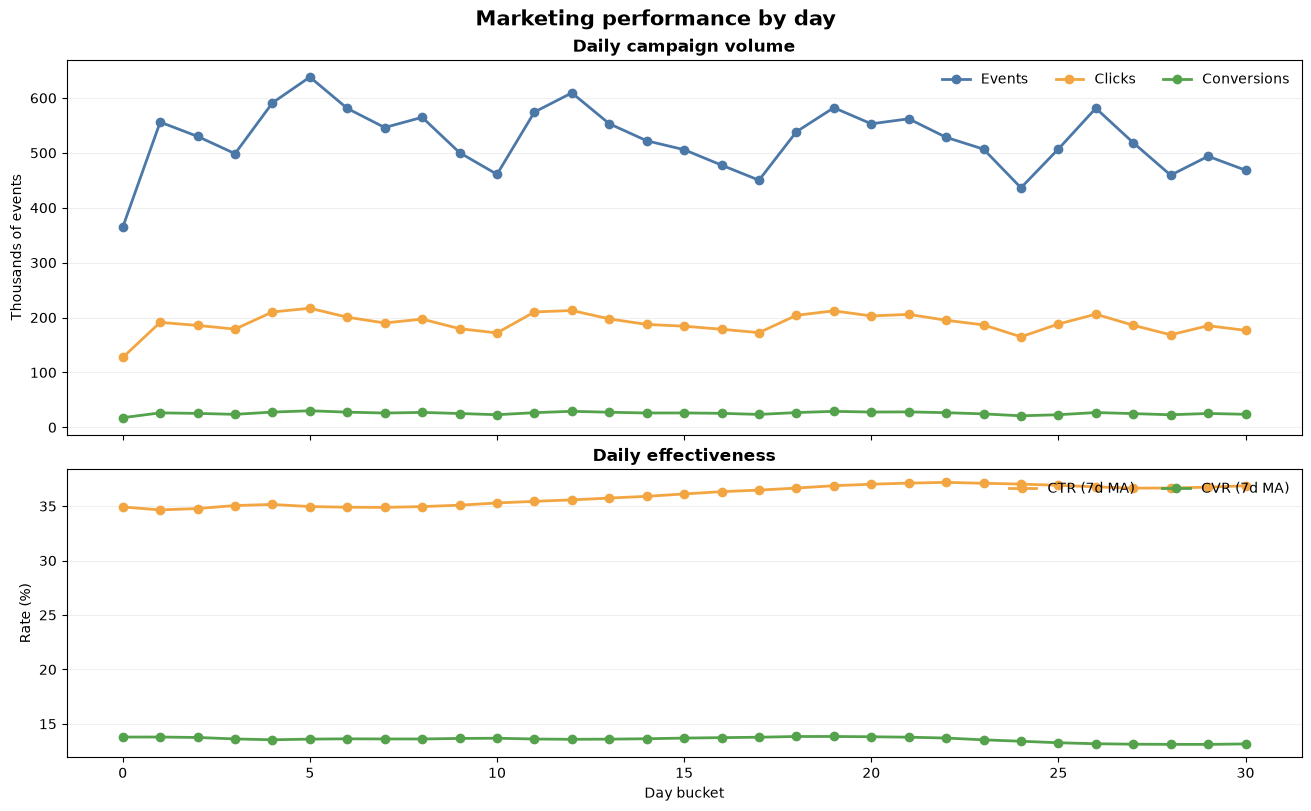

In [17]:
import matplotlib.pyplot as plt

plot_df = data.copy()
if 'timestamp' in plot_df.columns:
    plot_df['day'] = plot_df['timestamp'] // 86_400
else:
    plot_df['day'] = plot_df['days'].round().astype(int)

daily = (
    plot_df.groupby('day', as_index=False)
    .agg(
        events=('day', 'size'),
        clicks=('click', 'sum'),
        conversions=('conversion', 'sum'),
        spend=('cost', 'sum'),
    )
    .sort_values('day')
    .reset_index(drop=True)
)

daily['ctr'] = daily['clicks'] / daily['events'] * 100
daily['cvr'] = daily['conversions'] / daily['clicks'].replace(0, float('nan')) * 100

daily['ctr_ma'] = daily['ctr'].rolling(7, min_periods=1).mean()
daily['cvr_ma'] = daily['cvr'].rolling(7, min_periods=1).mean()

fig, axes = plt.subplots(
    2, 1, figsize=(13, 8), sharex=True,
    constrained_layout=True,
    gridspec_kw={'height_ratios': [1.3, 1]},
)

axes[0].plot(daily['day'], daily['events'] / 1000, marker='o', linewidth=2, color='#4C78A8', label='Events')
axes[0].plot(daily['day'], daily['clicks'] / 1000, marker='o', linewidth=2, color='#F2A541', label='Clicks')
axes[0].plot(daily['day'], daily['conversions'] / 1000, marker='o', linewidth=2, color='#54A24B', label='Conversions')
axes[0].set_title('Daily campaign volume', weight='bold')
axes[0].set_ylabel('Thousands of events')
axes[0].legend(frameon=False, ncol=3, loc='upper right')
axes[0].grid(axis='y', alpha=0.2)

axes[1].plot(daily['day'], daily['ctr_ma'], marker='o', linewidth=2, color='#F2A541', label='CTR (7d MA)')
axes[1].plot(daily['day'], daily['cvr_ma'], marker='o', linewidth=2, color='#54A24B', label='CVR (7d MA)')
axes[1].set_title('Daily effectiveness', weight='bold')
axes[1].set_xlabel('Day bucket')
axes[1].set_ylabel('Rate (%)')
axes[1].legend(frameon=False, ncol=2, loc='upper right')
axes[1].grid(axis='y', alpha=0.2)

fig.suptitle('Marketing performance by day', fontsize=15, weight='bold')
plt.show()


**Removing Data That gonna cause Leakage**

   *Data :* conversion_timestamp , conversion_id, attribution 

In [18]:
leakage_data = ['conversion_timestamp' , 'conversion_id', 'attribution'] 

data = data.drop(columns= leakage_data)

In [19]:
data.columns

Index(['timestamp', 'campaign', 'conversion', 'click', 'click_pos', 'click_nb',
       'cost', 'cpo', 'time_since_last_click', 'days'],
      dtype='str')

In [20]:
conversion_corr = data.corr()['conversion'].to_frame()


conversion_corr = conversion_corr.sort_values(
    by='conversion',
    ascending=False
)



<Axes: >

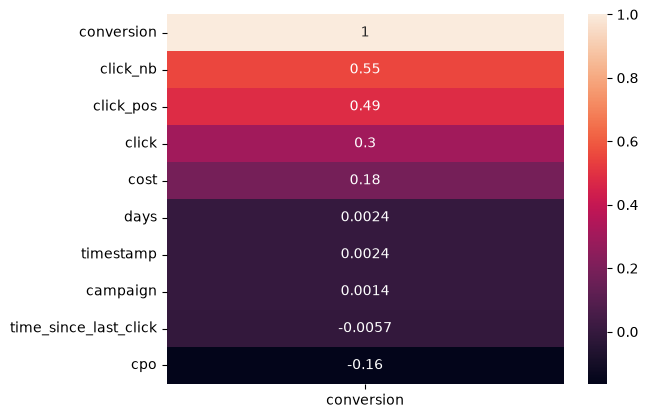

In [21]:
import seaborn as sns  

sns.heatmap(conversion_corr, annot=True)


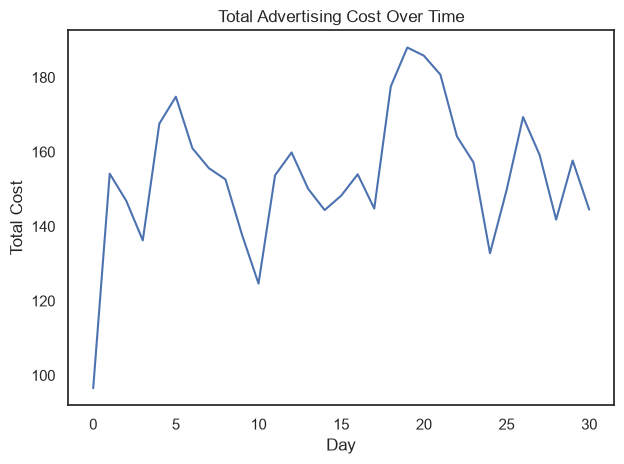

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

data["day_group"] = data["days"].astype("int32")

daily_cost = (
    data.groupby("day_group")["cost"]
    .sum()
    .reset_index()
)
sns.set_theme(
    style="white",
    context="notebook",
    font="sans-serif"
)
sns.lineplot(data=daily_cost, x="day_group", y="cost")

plt.title("Total Advertising Cost Over Time")
plt.xlabel("Day")
plt.ylabel("Total Cost")
plt.tight_layout()
plt.show()

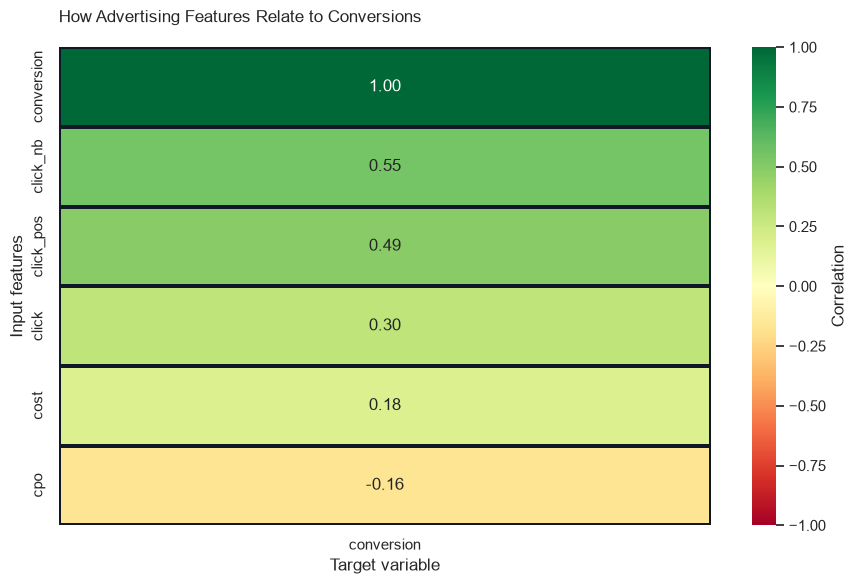

In [23]:
features = ["cpo", "cost", "click", "click_pos", "click_nb"]

corr = data[features + ["conversion"]].corr(numeric_only=True)

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr[["conversion"]].sort_values(
        by="conversion",
        ascending=False
    ),
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    linewidths=1.5,
    linecolor="#101827",
    cbar_kws={"label": "Correlation"}
)

plt.title("How Advertising Features Relate to Conversions", loc="left", pad=18)
plt.xlabel("Target variable")
plt.ylabel("Input features")
plt.tight_layout()
plt.show()

In [24]:
#data.to_csv("../data/marketing_data.csv", index=False)

In [25]:
data['click_pos'].value_counts().sum()

np.int64(16260601)